In [1]:
!pip install kagglehub

  Using cached certifi-2026.10.23-py3-none-any.whl.metadata (2.5 kB)
  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
Using cached certifi-2026.10.23-py3-none-any.whl (135 kB)
Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl (456 kB)

   ---------------------------------------- 0/4 [protobuf]
   ---------------------------------------- 0/4 [protobuf]
   ---------------------------------------- 0/4 [protobuf]
   ---------------------------------------- 0/4 [protobuf]
   ---------------------------------------- 0/4 [protobuf]
   ---------------------------------------- 0/4 [protobuf]
   ---------------------------------------- 0/4 [protobuf]
   ---------------------------------------- 0/4 [protobuf]
   ---------------------------------------- 0/4 [protobuf]
   ---------------------------------------- 0/4 [protobuf]
   ---------------------------------------- 0/4 [protobuf]
   ---------------------------------------- 0/4 [protobuf]
   ---------------------


[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: C:\Users\User\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [2]:
import kagglehub

# Download the latest version of the Olist dataset
path = kagglehub.dataset_download("olistbr/brazilian-ecommerce")

print("Path to dataset files:", path)

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 42.6M/42.6M [02:29<00:00, 298kB/s]

Extracting files...


Path to dataset files: C:\Users\User\.cache\kagglehub\datasets\olistbr\brazilian-ecommerce\versions\2


In [3]:
import os

# List all downloaded files
for file in os.listdir(path):
    print(file)

olist_customers_dataset.csv
olist_geolocation_dataset.csv
olist_orders_dataset.csv
olist_order_items_dataset.csv
olist_order_payments_dataset.csv
olist_order_reviews_dataset.csv
olist_products_dataset.csv
olist_sellers_dataset.csv
product_category_name_translation.csv


In [4]:
import pandas as pd
import glob
import os

csv_files = glob.glob(os.path.join(path, "*.csv"))

for file in csv_files:
    df = pd.read_csv(file)

    print(f"\nFile: {os.path.basename(file)}")
    print(f"Rows: {df.shape[0]}")
    print(f"Columns: {df.shape[1]}")
    print("-" * 50)


File: olist_customers_dataset.csv
Rows: 99441
Columns: 5
--------------------------------------------------

File: olist_geolocation_dataset.csv
Rows: 1000163
Columns: 5
--------------------------------------------------

File: olist_orders_dataset.csv
Rows: 99441
Columns: 8
--------------------------------------------------

File: olist_order_items_dataset.csv
Rows: 112650
Columns: 7
--------------------------------------------------

File: olist_order_payments_dataset.csv
Rows: 103886
Columns: 5
--------------------------------------------------

File: olist_order_reviews_dataset.csv
Rows: 99224
Columns: 7
--------------------------------------------------

File: olist_products_dataset.csv
Rows: 32951
Columns: 9
--------------------------------------------------

File: olist_sellers_dataset.csv
Rows: 3095
Columns: 4
--------------------------------------------------

File: product_category_name_translation.csv
Rows: 71
Columns: 2
--------------------------------------------------


In [5]:
import pandas as pd
import os

# Load the main datasets
orders = pd.read_csv(os.path.join(path, "olist_orders_dataset.csv"))
order_items = pd.read_csv(os.path.join(path, "olist_order_items_dataset.csv"))
customers = pd.read_csv(os.path.join(path, "olist_customers_dataset.csv"))
products = pd.read_csv(os.path.join(path, "olist_products_dataset.csv"))
sellers = pd.read_csv(os.path.join(path, "olist_sellers_dataset.csv"))
payments = pd.read_csv(os.path.join(path, "olist_order_payments_dataset.csv"))

# Load product category translation
category_translation = pd.read_csv(
    os.path.join(path, "product_category_name_translation.csv")
)

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [6]:
datasets = {
    "Orders": orders,
    "Order Items": order_items,
    "Customers": customers,
    "Products": products,
    "Sellers": sellers,
    "Payments": payments,
    "Category Translation": category_translation
}

for name, df in datasets.items():
    print(f"\n{'=' * 50}")
    print(f"{name}")
    print(f"Shape: {df.shape}")
    print("\nColumns:")
    print(df.columns.tolist())
    print("\nMissing values:")
    print(df.isnull().sum())


Orders
Shape: (99441, 8)

Columns:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

Missing values:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Order Items
Shape: (112650, 7)

Columns:
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

Missing values:
order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

Customers
Shape: (99441, 5)

Columns:
['customer_id', 'customer_unique_id', 'customer

In [7]:
# Check the distribution of order statuses
print("Order status distribution:")
print(orders["order_status"].value_counts(dropna=False))

print("\nDelivery date availability by order status:")
print(
    orders.groupby("order_status")[
        "order_delivered_customer_date"
    ].apply(lambda x: x.isna().sum())
)

Order status distribution:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Delivery date availability by order status:
order_status
approved          2
canceled        619
created           5
delivered         8
invoiced        314
processing      301
shipped        1107
unavailable     609
Name: order_delivered_customer_date, dtype: int64


In [8]:
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    orders[col] = pd.to_datetime(orders[col], errors="coerce")

# Calculate actual delivery time difference in days
orders["delivery_difference_days"] = (
    orders["order_delivered_customer_date"]
    - orders["order_estimated_delivery_date"]
).dt.total_seconds() / (60 * 60 * 24)

print("Delivery difference summary:")
print(orders["delivery_difference_days"].describe())

print("\nOrders with actual delivery dates:")
print(orders["order_delivered_customer_date"].notna().sum())

Delivery difference summary:
count    96476.000000
mean       -11.179120
std         10.186113
min       -146.016123
25%        -16.244384
50%        -11.948941
75%         -6.390000
max        188.975081
Name: delivery_difference_days, dtype: float64

Orders with actual delivery dates:
96476


In [9]:
# Keep only delivered orders with a valid actual delivery date
model_orders = orders[
    (orders["order_status"] == "delivered") &
    (orders["order_delivered_customer_date"].notna())
].copy()

# Create target variable
model_orders["delivery_status"] = (
    model_orders["order_delivered_customer_date"] >
    model_orders["order_estimated_delivery_date"]
).astype(int)

# Replace numeric labels with readable labels for inspection
model_orders["delivery_status_label"] = (
    model_orders["delivery_status"]
    .map({0: "On Time", 1: "Delayed"})
)

print("Eligible orders:", len(model_orders))

print("\nDelivery status distribution:")
print(model_orders["delivery_status_label"].value_counts())

print("\nDelivery status percentages:")
print(
    model_orders["delivery_status_label"]
    .value_counts(normalize=True).mul(100).round(2)
)

Eligible orders: 96470

Delivery status distribution:
delivery_status_label
On Time    88644
Delayed     7826
Name: count, dtype: int64

Delivery status percentages:
delivery_status_label
On Time    91.89
Delayed     8.11
Name: proportion, dtype: float64


In [10]:
# Aggregate order items: one row per order
item_summary = order_items.groupby("order_id").agg(
    item_count=("order_item_id", "count"),
    total_price=("price", "sum"),
    total_freight=("freight_value", "sum"),
    average_item_price=("price", "mean"),
    unique_sellers=("seller_id", "nunique")
).reset_index()

print("Order item summary shape:", item_summary.shape)
print(item_summary.head())

Order item summary shape: (98666, 6)
                           order_id  item_count  total_price  total_freight  \
0  00010242fe8c5a6d1ba2dd792cb16214           1        58.90          13.29   
1  00018f77f2f0320c557190d7a144bdd3           1       239.90          19.93   
2  000229ec398224ef6ca0657da4fc703e           1       199.00          17.87   
3  00024acbcdf0a6daa1e931b038114c75           1        12.99          12.79   
4  00042b26cf59d7ce69dfabb4e55b4fd9           1       199.90          18.14   

   average_item_price  unique_sellers  
0               58.90               1  
1              239.90               1  
2              199.00               1  
3               12.99               1  
4              199.90               1  


In [11]:
# Aggregate payments: one row per order
payment_summary = payments.groupby("order_id").agg(
    total_payment=("payment_value", "sum"),
    max_installments=("payment_installments", "max"),
    payment_types=("payment_type", "nunique")
).reset_index()

# Most common payment type for each order
main_payment_type = (
    payments.groupby("order_id")["payment_type"]
    .agg(lambda x: x.mode().iloc[0])
    .reset_index(name="main_payment_type")
)

payment_summary = payment_summary.merge(
    main_payment_type,
    on="order_id",
    how="left"
)

print("Payment summary shape:", payment_summary.shape)
print(payment_summary.head())

Payment summary shape: (99440, 5)
                           order_id  total_payment  max_installments  \
0  00010242fe8c5a6d1ba2dd792cb16214          72.19                 2   
1  00018f77f2f0320c557190d7a144bdd3         259.83                 3   
2  000229ec398224ef6ca0657da4fc703e         216.87                 5   
3  00024acbcdf0a6daa1e931b038114c75          25.78                 2   
4  00042b26cf59d7ce69dfabb4e55b4fd9         218.04                 3   

   payment_types main_payment_type  
0              1       credit_card  
1              1       credit_card  
2              1       credit_card  
3              1       credit_card  
4              1       credit_card  


In [12]:
# Start with eligible orders and retain the target
final_df = model_orders[
    ["order_id", "customer_id", "order_purchase_timestamp",
     "order_estimated_delivery_date", "delivery_status"]
].copy()

# Merge customer information
final_df = final_df.merge(
    customers[[
        "customer_id",
        "customer_city",
        "customer_state",
        "customer_zip_code_prefix"
    ]],
    on="customer_id",
    how="left"
)

# Merge item summary
final_df = final_df.merge(
    item_summary,
    on="order_id",
    how="left"
)

# Merge payment summary
final_df = final_df.merge(
    payment_summary,
    on="order_id",
    how="left"
)

print("Final dataset shape:", final_df.shape)
print("Unique orders:", final_df["order_id"].nunique())
print("\nFirst five rows:")
display(final_df.head())

Final dataset shape: (96470, 17)
Unique orders: 96470

First five rows:


,order_id,customer_id,order_purchase_timestamp,order_estimated_delivery_date,delivery_status,customer_city,customer_state,customer_zip_code_prefix,item_count,total_price,total_freight,average_item_price,unique_sellers,total_payment,max_installments,payment_types,main_payment_type
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,2017-10-02 10:56:33,2017-10-18,0,sao paulo,SP,3149,1,29.99,8.72,29.99,1,38.71,1.0,2.0,voucher
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,2018-07-24 20:41:37,2018-08-13,0,barreiras,BA,47813,1,118.70,22.76,118.70,1,141.46,1.0,1.0,boleto
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,2018-08-08 08:38:49,2018-09-04,0,vianopolis,GO,75265,1,159.90,19.22,159.90,1,179.12,3.0,1.0,credit_card
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,2017-11-18 19:28:06,2017-12-15,0,sao goncalo do amarante,RN,59296,1,45.00,27.20,45.00,1,72.20,1.0,1.0,credit_card
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,2018-02-13 21:18:39,2018-02-26,0,santo andre,SP,9195,1,19.90,8.72,19.90,1,28.62,1.0,1.0,credit_card


In [13]:
# Check missing values in the integrated dataset
missing_summary = pd.DataFrame({
    "Missing Count": final_df.isnull().sum(),
    "Missing Percentage": (
        final_df.isnull().mean() * 100
    ).round(2)
})

print(missing_summary)

                               Missing Count  Missing Percentage
order_id                                   0                 0.0
customer_id                                0                 0.0
order_purchase_timestamp                   0                 0.0
order_estimated_delivery_date              0                 0.0
delivery_status                            0                 0.0
customer_city                              0                 0.0
customer_state                             0                 0.0
customer_zip_code_prefix                   0                 0.0
item_count                                 0                 0.0
total_price                                0                 0.0
total_freight                              0                 0.0
average_item_price                         0                 0.0
unique_sellers                             0                 0.0
total_payment                              1                 0.0
max_installments         

In [14]:
print("Orders without item information:",
      final_df["item_count"].isna().sum())

print("Orders without payment information:",
      final_df["total_payment"].isna().sum())

print("\nOrders with missing item details:")
display(final_df[final_df["item_count"].isna()].head())

print("\nOrders with missing payment details:")
display(final_df[final_df["total_payment"].isna()].head())

Orders without item information: 0
Orders without payment information: 1

Orders with missing item details:


,order_id,customer_id,order_purchase_timestamp,order_estimated_delivery_date,delivery_status,customer_city,customer_state,customer_zip_code_prefix,item_count,total_price,total_freight,average_item_price,unique_sellers,total_payment,max_installments,payment_types,main_payment_type



Orders with missing payment details:


,order_id,customer_id,order_purchase_timestamp,order_estimated_delivery_date,delivery_status,customer_city,customer_state,customer_zip_code_prefix,item_count,total_price,total_freight,average_item_price,unique_sellers,total_payment,max_installments,payment_types,main_payment_type
29809,bfbd0f9bdef84302105ad712db648a6c,86dc2ffce2dfff336de2f386a786e574,2016-09-15 12:16:38,2016-10-04,1,sao joaquim da barra,SP,14600,3,134.97,8.49,44.99,1,NaN,NaN,NaN,NaN


In [15]:
# Extract features from purchase timestamp
final_df["purchase_year"] = (
    final_df["order_purchase_timestamp"].dt.year
)

final_df["purchase_month"] = (
    final_df["order_purchase_timestamp"].dt.month
)

final_df["purchase_day"] = (
    final_df["order_purchase_timestamp"].dt.day
)

final_df["purchase_day_of_week"] = (
    final_df["order_purchase_timestamp"].dt.dayofweek
)

final_df["purchase_hour"] = (
    final_df["order_purchase_timestamp"].dt.hour
)

# Estimated delivery window in days
final_df["estimated_delivery_days"] = (
    final_df["order_estimated_delivery_date"]
    - final_df["order_purchase_timestamp"]
).dt.total_seconds() / 86400

display(final_df.head())

,order_id,customer_id,order_purchase_timestamp,order_estimated_delivery_date,delivery_status,customer_city,customer_state,customer_zip_code_prefix,item_count,total_price,...,total_payment,max_installments,payment_types,main_payment_type,purchase_year,purchase_month,purchase_day,purchase_day_of_week,purchase_hour,estimated_delivery_days
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,2017-10-02 10:56:33,2017-10-18,0,sao paulo,SP,3149,1,29.99,...,38.71,1.0,2.0,voucher,2017,10,2,0,10,15.544063
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,2018-07-24 20:41:37,2018-08-13,0,barreiras,BA,47813,1,118.70,...,141.46,1.0,1.0,boleto,2018,7,24,1,20,19.137766
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,2018-08-08 08:38:49,2018-09-04,0,vianopolis,GO,75265,1,159.90,...,179.12,3.0,1.0,credit_card,2018,8,8,2,8,26.639711
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,2017-11-18 19:28:06,2017-12-15,0,sao goncalo do amarante,RN,59296,1,45.00,...,72.20,1.0,1.0,credit_card,2017,11,18,5,19,26.188819
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,2018-02-13 21:18:39,2018-02-26,0,santo andre,SP,9195,1,19.90,...,28.62,1.0,1.0,credit_card,2018,2,13,1,21,12.112049


In [16]:
# Handle the single missing payment record
final_df["total_payment"] = final_df["total_payment"].fillna(
    final_df["total_price"] + final_df["total_freight"]
)

final_df["max_installments"] = final_df["max_installments"].fillna(0)

final_df["payment_types"] = final_df["payment_types"].fillna(0)

final_df["main_payment_type"] = final_df["main_payment_type"].fillna(
    "unknown"
)

print("Remaining missing values:")
print(final_df.isnull().sum().sum())

Remaining missing values:
0


In [17]:
print("Dataset shape:", final_df.shape)

print("\nMissing values:")
print(final_df.isnull().sum().sum())

print("\nDuplicate orders:")
print(final_df["order_id"].duplicated().sum())

print("\nTarget distribution:")
print(final_df["delivery_status"].value_counts())

Dataset shape: (96470, 23)

Missing values:
0

Duplicate orders:
0

Target distribution:
delivery_status
0    88644
1     7826
Name: count, dtype: int64


In [18]:
final_df.to_csv("olist_integrated_dataset.csv", index=False)

print("Integrated dataset saved successfully!")

Integrated dataset saved successfully!


EXPLORATORY DATA ANALYSIS(EDA)

In [19]:
# Select numerical columns
numerical_columns = [
    "item_count",
    "total_price",
    "total_freight",
    "average_item_price",
    "unique_sellers",
    "total_payment",
    "max_installments",
    "payment_types",
    "customer_zip_code_prefix",
    "purchase_year",
    "purchase_month",
    "purchase_day",
    "purchase_day_of_week",
    "purchase_hour",
    "estimated_delivery_days"
]

# Generate descriptive statistics
descriptive_stats = final_df[numerical_columns].describe().T

display(descriptive_stats.round(2))

,count,mean,std,min,25%,50%,75%,max
item_count,96470.0,1.14,0.54,1.00,1.00,1.00,1.00,21.00
total_price,96470.0,137.04,209.05,0.85,45.90,86.50,149.90,13440.00
total_freight,96470.0,22.79,21.56,0.00,13.85,17.17,24.02,1794.96
average_item_price,96470.0,125.23,189.70,0.85,41.90,79.00,139.90,6735.00
unique_sellers,96470.0,1.01,0.12,1.00,1.00,1.00,1.00,5.00
total_payment,96470.0,159.86,218.82,9.59,61.88,105.28,176.33,13664.08
max_installments,96470.0,2.93,2.71,0.00,1.00,2.00,4.00,24.00
payment_types,96470.0,1.02,0.15,0.00,1.00,1.00,1.00,2.00
customer_zip_code_prefix,96470.0,35199.20,29839.79,1003.00,11355.00,24436.00,59056.00,99980.00
purchase_year,96470.0,2017.54,0.50,2016.00,2017.00,2018.00,2018.00,2018.00


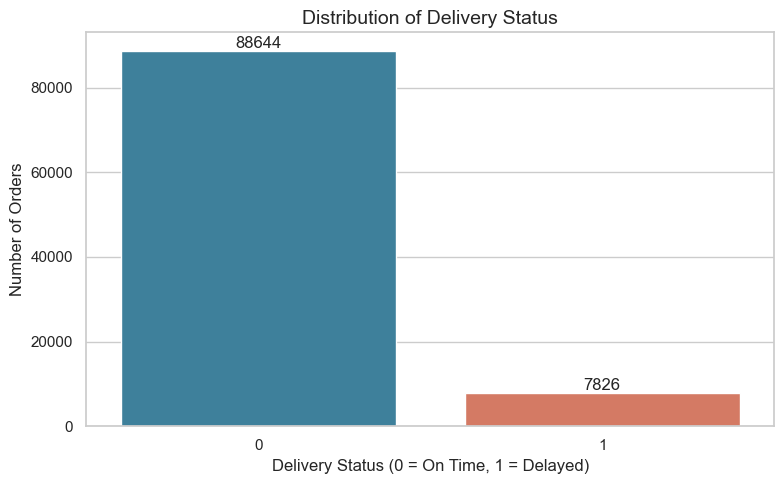

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=final_df,
    x="delivery_status",
    hue="delivery_status",
    palette=["#2E86AB", "#E76F51"],
    legend=False
)

plt.title("Distribution of Delivery Status", fontsize=14)
plt.xlabel("Delivery Status (0 = On Time, 1 = Delayed)")
plt.ylabel("Number of Orders")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

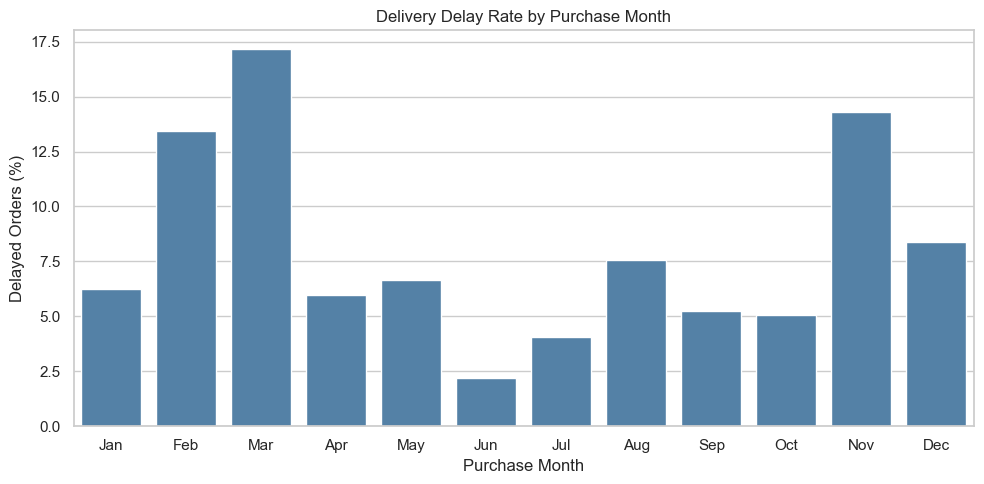

,purchase_month,delay_percentage
0,1,6.23
1,2,13.41
2,3,17.15
3,4,5.96
4,5,6.64
5,6,2.21
6,7,4.08
7,8,7.58
8,9,5.23
9,10,5.06


In [21]:
# Calculate delay rate by purchase month
monthly_delay = (
    final_df.groupby("purchase_month")["delivery_status"]
    .mean()
    .mul(100)
    .reset_index(name="delay_percentage")
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=monthly_delay,
    x="purchase_month",
    y="delay_percentage",
    color="steelblue"
)

plt.title("Delivery Delay Rate by Purchase Month")
plt.xlabel("Purchase Month")
plt.ylabel("Delayed Orders (%)")
plt.xticks(range(12), [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
])

plt.tight_layout()
plt.show()

display(monthly_delay.round(2))

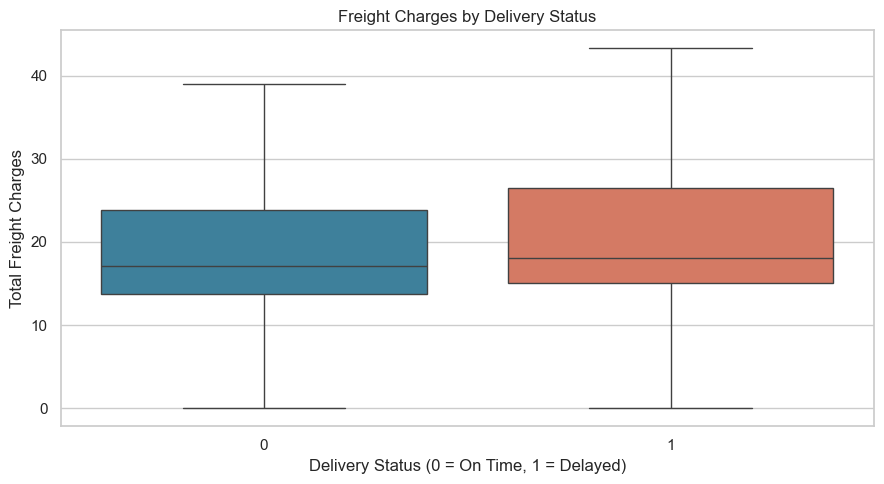

In [22]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=final_df,
    x="delivery_status",
    y="total_freight",
    hue="delivery_status",
    palette=["#2E86AB", "#E76F51"],
    legend=False,
    showfliers=False
)

plt.title("Freight Charges by Delivery Status")
plt.xlabel("Delivery Status (0 = On Time, 1 = Delayed)")
plt.ylabel("Total Freight Charges")

plt.tight_layout()
plt.show()

In [23]:
monthly_analysis = final_df.groupby("purchase_month").agg(
    total_orders=("delivery_status", "count"),
    delayed_orders=("delivery_status", "sum"),
    delay_rate=("delivery_status", "mean")
).reset_index()

monthly_analysis["delay_rate"] *= 100

display(monthly_analysis.round(2))

,purchase_month,total_orders,delayed_orders,delay_rate
0,1,7819,487,6.23
1,2,8208,1101,13.41
2,3,9549,1638,17.15
3,4,9101,542,5.96
4,5,10294,684,6.64
5,6,9231,204,2.21
6,7,10028,409,4.08
7,8,10544,799,7.58
8,9,4151,217,5.23
9,10,4743,240,5.06


In [24]:
weekday_names = {
    0: "Monday",
    1: "Tuesday",
    2: "Wednesday",
    3: "Thursday",
    4: "Friday",
    5: "Saturday",
    6: "Sunday"
}

weekday_analysis = final_df.groupby("purchase_day_of_week").agg(
    total_orders=("delivery_status", "count"),
    delayed_orders=("delivery_status", "sum"),
    delay_rate=("delivery_status", "mean")
).reset_index()

weekday_analysis["day"] = weekday_analysis[
    "purchase_day_of_week"
].map(weekday_names)

weekday_analysis["delay_rate"] *= 100

display(weekday_analysis[[
    "day", "total_orders", "delayed_orders", "delay_rate"
]].round(2))

,day,total_orders,delayed_orders,delay_rate
0,Monday,15701,1421,9.05
1,Tuesday,15502,1316,8.49
2,Wednesday,15074,1176,7.80
3,Thursday,14322,1084,7.57
4,Friday,13684,1156,8.45
5,Saturday,10555,802,7.60
6,Sunday,11632,871,7.49


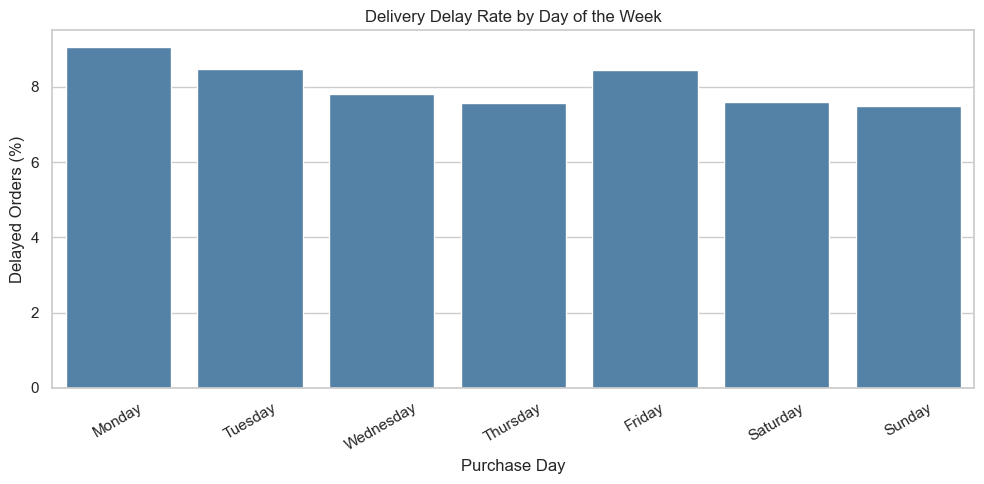

In [25]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=weekday_analysis,
    x="day",
    y="delay_rate",
    color="steelblue",
    order=[
        "Monday", "Tuesday", "Wednesday",
        "Thursday", "Friday", "Saturday", "Sunday"
    ]
)

plt.title("Delivery Delay Rate by Day of the Week")
plt.xlabel("Purchase Day")
plt.ylabel("Delayed Orders (%)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()